In [26]:
# Setup
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

import torch.nn.functional as F

import matplotlib.pyplot as plt

import time

print("Successfully imported modules!")

Successfully imported modules!


In [7]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Apple GPU available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Device:", device)

PyTorch: 2.14.1
CUDA available: False
Apple GPU available: True
Device: mps


In [8]:
def benchmark(device, size=1024, repeats=20):
    a = torch.randn(size, size, device=device)
    b = torch.randn(size, size, device=device)

    # Warm-up
    for _ in range(3):
        _ = a @ b

    if device == "mps":
        torch.mps.synchronize()

    start = time.perf_counter()

    for _ in range(repeats):
        c = a @ b

    # GPU operations can be asynchronous
    if device == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start

    return elapsed / repeats * 1000

cpu_ms = benchmark("cpu")
mps_ms = benchmark("mps")

print(f"CPU average: {cpu_ms:.2f} ms")
print(f"MPS average: {mps_ms:.2f} ms")
print(f"CPU/MPS time ratio: {cpu_ms / mps_ms:.2f}x")

CPU average: 1.46 ms
MPS average: 1.02 ms
CPU/MPS time ratio: 1.44x


# GPT 2 Experimentation:

https://huggingface.co/openai-community/gpt2/tree/main

```
{
  "activation_function": "gelu_new",
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_layer": 12,
  "n_positions": 1024,
  "resid_pdrop": 0.1,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "vocab_size": 50257
}
```

In [9]:
# We'll use GPT-2 (124M params) -- small enough to run on CPU
MODEL_NAME = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model.eval()  # inference mode -- disables training-only behavior like dropout

print(f"Model: {MODEL_NAME}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")   
print(f"Vocabulary size: {tokenizer.vocab_size:,} tokens")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model: gpt2
Parameters: 124,439,808
Vocabulary size: 50,257 tokens


#### Remember:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

model.parameters()

tokenizer.vocab_size

## 1. Tokenization (text to numbers)

In [11]:
# Tokenize a prompt and see what comes out
prompt = "Kubernetes pods are scheduled by the"

token_ids = tokenizer.encode(prompt)
tokens = [tokenizer.decode(tid) for tid in token_ids]

print(f"Input text:  {prompt!r}")
print(f"Token IDs:   {token_ids}")
print(f"Tokens:      {tokens}")
print(f"Token count: {len(token_ids)}")
print()

# Show the mapping side by side
for tid, tok in zip(token_ids, tokens):
    print(f"  {tid:>6d} → {tok!r}")

Input text:  'Kubernetes pods are scheduled by the'
Token IDs:   [42, 18478, 3262, 274, 37185, 389, 7530, 416, 262]
Tokens:      ['K', 'uber', 'net', 'es', ' pods', ' are', ' scheduled', ' by', ' the']
Token count: 9

      42 → 'K'
   18478 → 'uber'
    3262 → 'net'
     274 → 'es'
   37185 → ' pods'
     389 → ' are'
    7530 → ' scheduled'
     416 → ' by'
     262 → ' the'


In [12]:
# Different text, different tokenizations
# Notice: common words get one token, rare words get split into pieces
examples = [
    "the",
    "Kubernetes",
    "autoscaler",
    "NVIDIA",
    "192.168.1.1",
]

for text in examples:
    ids = tokenizer.encode(text)
    pieces = [tokenizer.decode(i) for i in ids]
    print(f"  {text:<20s} → {len(ids)} token(s): {pieces}")

  the                  → 1 token(s): ['the']
  Kubernetes           → 4 token(s): ['K', 'uber', 'net', 'es']
  autoscaler           → 4 token(s): ['aut', 'os', 'cal', 'er']
  NVIDIA               → 1 token(s): ['NVIDIA']
  192.168.1.1          → 7 token(s): ['192', '.', '168', '.', '1', '.', '1']


## 2. Forward Pass

In [13]:
# Run one forward pass and look at the raw output
prompt = "Kubernetes pods are scheduled by the"
inputs = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():  # no need to track gradients during inference
    outputs = model(**inputs)

# outputs.logits shape: [batch_size, sequence_length, vocab_size]
logits = outputs.logits
print(f"Input tokens:  {inputs['input_ids'].shape[1]}")
print(f"Logits shape:  {logits.shape}")
print(f"  → batch=1, seq_len={logits.shape[1]}, vocab={logits.shape[2]}")
print()

# We care about the LAST position -- that's the prediction for the NEXT token
next_token_logits = logits[0, -1, :]  # shape: [vocab_size]
print(f"Logits for next token: {next_token_logits.shape[0]} scores")
print(f"  min={next_token_logits.min():.2f}, max={next_token_logits.max():.2f}")

Input tokens:  9
Logits shape:  torch.Size([1, 9, 50257])
  → batch=1, seq_len=9, vocab=50257

Logits for next token: 50257 scores
  min=-125.86, max=-98.24


In [27]:
# Convert logits to probabilities and see the top predictions
probs = F.softmax(next_token_logits, dim=-1)

# Top 10 most likely next tokens
top_probs, top_ids = torch.topk(probs, k=10)

print(f"Prompt: {prompt!r}")
print(f"\nTop 10 predictions for the next token:\n")
for prob, tid in zip(top_probs, top_ids):
    token_text = tokenizer.decode(tid)
    print(f"  {prob:>6.2%}  →  {token_text!r}")

Prompt: 'Kubernetes pods are scheduled by the'

Top 10 predictions for the next token:

  20.02%  →  ' end'
   5.59%  →  ' time'
   2.03%  →  ' same'
   1.31%  →  ' start'
   1.29%  →  ' day'
   1.20%  →  ' company'
   1.06%  →  ' next'
   0.79%  →  ' beginning'
   0.69%  →  ' server'
   0.62%  →  ' following'


In [21]:
# Greedy decoding: just pick the most likely token
next_token_id = torch.argmax(next_token_logits).item()
next_token_text = tokenizer.decode(next_token_id)

print(f"Prompt:     {prompt!r}")
print(f"Next token: {next_token_text!r} (id={next_token_id})")
print(f"Full text:  {prompt + next_token_text!r}")

Prompt:     'Kubernetes pods are scheduled by the'
Next token: ' end' (id=886)
Full text:  'Kubernetes pods are scheduled by the end'


#### Remember:

top_p, top_i = torch.topk(p, k=5)

PyTorch returns two things:
- top_p → the top 5 probability values.
- top_i → the indices of the tokens corresponding to those probabilities.

  temp=0.1  →  ' end' (100.0%), ' time' (0.0%), ' same' (0.0%), ' start' (0.0%), ' day' (0.0%)
  temp=0.5  →  ' end' (89.3%), ' time' (7.0%), ' same' (0.9%), ' start' (0.4%), ' day' (0.4%)
  temp=1.0  →  ' end' (20.0%), ' time' (5.6%), ' same' (2.0%), ' start' (1.3%), ' day' (1.3%)
  temp=2.0  →  ' end' (0.6%), ' time' (0.3%), ' same' (0.2%), ' start' (0.1%), ' day' (0.1%)


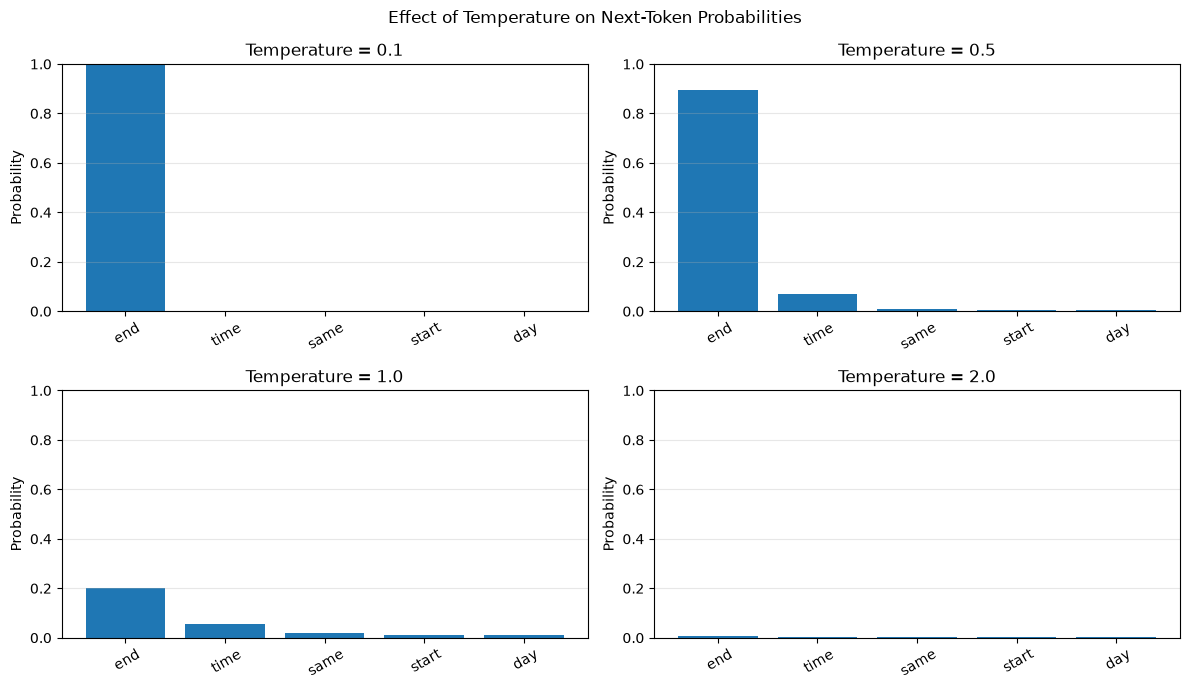

In [29]:
# Temperature affects randomness
# Low temperature → model is more confident (peaky distribution)
# High temperature → model is more random (flat distribution)

temperatures = [0.1, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, temp in zip(axes.flat, temperatures):
    scaled = next_token_logits / temp     # to scale them, we divide them by the temperature.
    p = F.softmax(scaled, dim=-1)

    top_p, top_i = torch.topk(p, k=5)   # selects the five tokens with the highest probabilities after applying temperature.
    tokens_str = ", ".join(f"{tokenizer.decode(i)!r} ({v:.1%})" for v, i in zip(top_p, top_i))
    print(f"  temp={temp:.1f}  →  {tokens_str}")
    
    tokens = [tokenizer.decode([i]) for i in top_i.tolist()]
    probs = top_p.tolist()

    ax.bar(tokens, probs)
    ax.set_title(f"Temperature = {temp}")
    ax.set_ylabel("Probability")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Effect of Temperature on Next-Token Probabilities")
plt.tight_layout()
plt.show()

#### Remember:

torch.argmax()

import torch.nn.functional as F

F.softmax()

## 3. Putting it all together

LLMs generate text **one token at a time** in a loop:

```
1. Tokenize the prompt
2. Forward pass → get logits for next token
3. Pick a token (decode/sample)
4. Append that token to the sequence
5. Go to step 2 (repeat until done)
```

This is called **autoregressive generation** — each token depends on all previous tokens.

In [32]:
# The full inference loop, step by step

prompt = "The sky is blue because"
input_ids = tokenizer.encode(prompt, return_tensors="pt")
generated = input_ids.clone()

NUM_TOKENS = 10

print(f"Prompt: {prompt!r}\n")
print("Generating tokens one at a time:\n")

for step in range(NUM_TOKENS):
    # Step 1: Forward pass -- feed the ENTIRE sequence so far
    with torch.no_grad():
        outputs = model(generated)     # Prefill stage: but no KV caching enabled
        # note: with KV caching enabled, it also stores the attention keys and values for reuse.

    # Step 2: Get logits for the last position
    next_logits = outputs.logits[0, -1, :]

    # Step 3: Greedy decode -- pick the most likely token
    next_id = torch.argmax(next_logits).unsqueeze(0).unsqueeze(0)

    # Step 4: Append to sequence
    generated = torch.cat([generated, next_id], dim=1)

    # Show progress
    new_token = tokenizer.decode(next_id[0])
    total_len = generated.shape[1]
    print(f"  step {step+1:>2d} | seq_len={total_len:>3d} | token={new_token!r}")

print(f"\nFinal output: \n{tokenizer.decode(generated[0])}")

Prompt: 'The sky is blue because'

Generating tokens one at a time:

  step  1 | seq_len=  6 | token=' of'
  step  2 | seq_len=  7 | token=' the'
  step  3 | seq_len=  8 | token=' sun'
  step  4 | seq_len=  9 | token='.'
  step  5 | seq_len= 10 | token='\n'
  step  6 | seq_len= 11 | token='\n'
  step  7 | seq_len= 12 | token='The'
  step  8 | seq_len= 13 | token=' sky'
  step  9 | seq_len= 14 | token=' is'
  step 10 | seq_len= 15 | token=' blue'

Final output: 
The sky is blue because of the sun.

The sky is blue


So there are two distinct inefficiencies in your loop:
1. Computing logits for every prompt position when you only need the last one.
2. Reprocessing the entire sequence after each generated token instead of reusing cached keys and values.

## Calculating cost 

The fundamental cost: the model must re-read the entire sequence for every new token it generates.  
Everything in inference optimization (KV caching, batching, speculative decoding) exists to reduce this cost.

| Stage | What happens | Cost driver |
|---|---|---|
| **Tokenize** | Text → integer IDs | Negligible |
| **Forward pass** | IDs → probability scores (logits) | Model size x sequence length |
| **Decode** | Pick one token from the scores | Negligible |
| **Loop** | Repeat forward+decode for each output token | Number of output tokens |

In [41]:
import time

prompt = "Deploying a containerized application to production requires"
input_ids = tokenizer.encode(prompt, return_tensors="pt")
generated = input_ids.clone()

NUM_TOKENS = 100
step_times = []

for step in range(NUM_TOKENS):
    start = time.perf_counter()
    with torch.no_grad():
        outputs = model(generated)
    next_id = torch.argmax(outputs.logits[0, -1, :]).unsqueeze(0).unsqueeze(0)
    generated = torch.cat([generated, next_id], dim=1)
    elapsed = time.perf_counter() - start
    step_times.append(elapsed)

print(f"Generated: {tokenizer.decode(generated[0])}")
print(f"\nTiming per step:")
print(f"  First token:  {step_times[0]*1000:.1f} ms")
print(f"  Last token:   {step_times[-1]*1000:.1f} ms")
print(f"  Total time:   {sum(step_times)*1000:.1f} ms")
print(f"  Avg per token: {sum(step_times)/len(step_times)*1000:.1f} ms")

Generated: Deploying a containerized application to production requires a lot of work.

The following is a list of the most common tasks that you'll need to do to deploy a containerized application to production:

Deploying a containerized application to production

Deploying a containerized application to production

Deploying a containerized application to production

Deploying a containerized application to production

Deploying a containerized application to production

Deploying a containerized application to production

Deploying a containerized application

Timing per step:
  First token:  32.2 ms
  Last token:   40.2 ms
  Total time:   2667.8 ms
  Avg per token: 26.7 ms


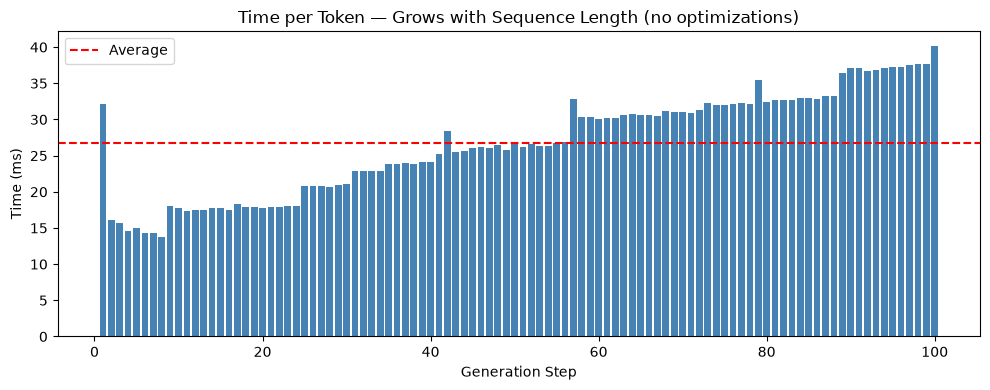

In [42]:
# Visualize: each step gets slower as the sequence grows

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, NUM_TOKENS + 1), [t * 1000 for t in step_times], color="steelblue")
ax.set_xlabel("Generation Step")
ax.set_ylabel("Time (ms)")
ax.set_title("Time per Token — Grows with Sequence Length (no optimizations)")
ax.axhline(y=sum(step_times)/len(step_times)*1000, color="red", linestyle="--", label="Average")
ax.legend()
plt.tight_layout()
plt.show()

Each step re-processes the entire sequence from scratch. As the sequence grows, each step takes longer. This is the naive baseline — later days will cover optimizations like the KV cache that fix this.

## Using a simple library model.generate() for the whole inference loop

In [45]:
# model.generate() wraps the same loop with optimizations and options
prompt = "Deploying a containerized application to production requires"
inputs = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=40,
        do_sample=False,  # greedy, same as our argmax
    )

print(tokenizer.decode(output_ids[0]))

Deploying a containerized application to production requires a lot of work.

The following is a list of the most common tasks that you'll need to do to deploy a containerized application to production:

Deploying a containerized application
